# Complete Lag 1–7 comparison — exploratory 2020 analysis

This notebook compares 13 controlled Dynamic Panel FE specifications. The main full-feature models remain unchanged.

- Single-lag specifications: cases today + one lag (1 through 7).
- Added-lag specifications: cases today + Lag 1 + one additional lag (2 through 7).
- Shared controls: 7/14-day commuting pressure, target weekday/month indicators and ZIP fixed effects.
- Same 585 ZIPs, 243 daily forecast dates, horizons 1/2/3, 60-calendar-day windows, 14-day warmup and weekly refitting.
- Every training target has occurred by its fit date. Retrospective onset data do not establish real-time reporting availability.

Coefficient inference uses only the predefined initial training fit. Date-level HAC score covariance accommodates cross-ZIP dependence and temporal dependence, with bandwidths 7 and 14, a t reference and Holm adjustment across 39 focal coefficient tests per bandwidth. Short samples and dynamic FE estimation bias limit inference. This does not reproduce System GMM, Sargan or Arellano–Bond tests.

Validation residual correlations are descriptive within-ZIP diagnostics, not GMM validity tests. Forecast comparisons use paired daily losses, whole-date block bootstrap intervals and Holm-adjusted HAC tests. Previously inspected 2020 development data are not an untouched test.


# Complete Lag 1–7 sweep: findings

These are exploratory 2020 validation results from controlled diagnostic FE specifications, not changes to the main full-feature models.

- L1 has the lowest MAE among the seven single-lag configurations (0.796049).
- L1+L2 has the lowest observed MAE (0.778484) and RMSE (1.433823) among the 13 configurations. Its MAE is 2.21% lower than L1. This is not a formal claim that it beats every other pair: tests below compare each configuration with L1 only.
- L1+L7 MAE is 0.788096, approximately 1.00% lower than L1, but it is not the best observed pair.
- L1+L2 endpoint direction agreement is 33.70%, versus 34.60% for L1. Better count error does not establish better direction prediction. The observed always-flat reference is approximately 56.8%.
- Initial-training coefficient p-values and validation predictive gains answer different questions and use different data periods. They must not be read as interchangeable evidence.
- Residual lag correlations describe remaining temporal dependence; they are not Arellano–Bond AR tests, and no GMM instrument-validity claim is made.
- All 1,365 fit audit rows satisfy latest training target <= fit date. Retrospective onset availability is still unverified.



In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
ROOT=Path(r'C:/Users/41240/OneDrive/鏂囨。/GitHub/practicum-project/Weikun')
def run(root=ROOT,output=Path('outputs/lag_sweep/results')):
 output=Path(output);output.mkdir(parents=True,exist_ok=True);(output/'figures').mkdir(exist_ok=True)
 ids=pd.read_csv(root/'fixed60_trajectory_outputs/fixed60_20261027/common_regions.csv',dtype={'zip':str}).zip.to_numpy();dates=pd.date_range('2020-03-01','2020-12-31')
 cols=['cases_today','cases_lag_1','cases_lag_7','cases_lag_14','nj_covid_pressure_7d','nj_covid_pressure_14d']
 f=pd.read_csv(root/'rolling_trajectory_outputs/inputs/nj_daily_features.csv.gz',usecols=['zip','date']+cols,dtype={'zip':str},parse_dates=['date']);f=f[f.zip.isin(ids)&f.date.isin(dates)]
 assert len(ids)==585 and not f.duplicated(['zip','date']).any()
 ar={c:f.pivot(index='zip',columns='date',values=c).reindex(index=ids,columns=dates).to_numpy(float) for c in cols};y=ar['cases_today'];assert np.isfinite(y).all()
 plt.rcParams.update({'font.family':'Arial','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
 rng=np.random.default_rng(20261104)
 for lag in range(2,7):
  v=np.full_like(y,np.nan);v[:,lag:]=y[:,:-lag];ar[f'cases_lag_{lag}']=v
 variants={f'L{k}':[f'cases_lag_{k}'] for k in range(1,8)}
 variants.update({f'L1_L{k}':['cases_lag_1',f'cases_lag_{k}'] for k in range(2,8)})
 inference=[];residuals=[]
 origins=np.flatnonzero((dates>='2020-04-30')&(dates<='2020-12-28'));truth=np.stack([y[:,origins+h] for h in [1,2,3]],2);pred={v:np.full_like(truth,np.nan) for v in variants};audit=[];coefs=[];first=dates.get_loc('2020-04-29')
 for fit in np.unique(first+7*((origins-first)//7)):
  lo=fit-59;batch=np.flatnonzero((origins>=fit)&(origins<fit+7))
  for hh,h in enumerate([1,2,3]):
   train=np.arange(lo+14,fit-h+1);assert train[-1]+h<=fit and np.all(origins[batch]>fit-1)
   target=dates+pd.Timedelta(days=h)
   for k in range(2,8):ar[f'weekday_{k}']=np.broadcast_to((target.dayofweek==k-1).astype(float),y.shape)
   for k in range(2,13):ar[f'month_{k}']=np.broadcast_to((target.month==k).astype(float),y.shape)
   yt=y[:,train+h];ym=yt.mean(1);yc=yt-ym[:,None]
   for name,lags in variants.items():
    features=['cases_today']+lags+cols[-2:]+[f'weekday_{k}' for k in range(2,8)]+[f'month_{k}' for k in range(2,13)]
    xx=np.stack([ar[c][:,train] for c in features],2);pp=np.stack([ar[c][:,origins[batch]] for c in features],2);assert np.isfinite(xx).all() and np.isfinite(pp).all();xm=xx.mean(1);xc=xx-xm[:,None];norm=np.sqrt((xc*xc).mean((0,1)));scale=np.where(norm>1e-10,norm,1);zz=(xc/scale).reshape(-1,len(features));keep=[];q=[]
    for k in range(len(features)):
     if norm[k]<1e-10:continue
     v=zz[:,k].copy()
     for _ in range(2):
      for u in q:v-=u*(u@v)
     length=np.linalg.norm(v)
     if length<=1e-7*np.sqrt(len(v)):continue
     keep.append(k);q.append(v/length)
    b=np.linalg.lstsq(zz[:,keep],yc.ravel(),rcond=None)[0]/scale[keep];ph=np.einsum('ntp,p->nt',pp[:,:,keep],b)+(ym-xm[:,keep]@b)[:,None];pred[name][:,batch,hh]=np.maximum(ph,0)
    # One predefined initial training fit: date-level HAC sandwich after within-ZIP transformation.
    if fit==first:
     X=xc[:,:,keep].reshape(-1,len(keep));err=(yc-np.einsum('ntp,p->nt',xc[:,:,keep],b))
     scores=np.einsum('ntp,nt->tp',xc[:,:,keep],err);bread=np.linalg.pinv(X.T@X)
     from scipy.stats import t as student_t
     for bandwidth in [7,14]:
      meat=scores.T@scores
      for lag in range(1,min(bandwidth,len(train)-1)+1):
       cross=scores[lag:].T@scores[:-lag];meat+=(1-lag/(bandwidth+1))*(cross+cross.T)
      cov=bread@meat@bread*(len(train)/(len(train)-1));se=np.sqrt(np.maximum(np.diag(cov),0))
      focal=lags[-1]
      if focal in [features[k] for k in keep]:
       j=[features[k] for k in keep].index(focal);stat=b[j]/se[j] if se[j]>0 else np.nan
       critical=student_t.ppf(.975,len(train)-1)
       inference.append(dict(variant=name,horizon=h,feature=focal,coefficient=b[j],standard_error=se[j],ci95_low=b[j]-critical*se[j],ci95_high=b[j]+critical*se[j],p_value=2*student_t.sf(abs(stat),len(train)-1),HAC_bandwidth=bandwidth,training_dates=len(train)))
    for k,coef in zip(keep,b):coefs.append(dict(variant=name,fit_date=str(dates[fit].date()),horizon=h,feature=features[k],coefficient=coef))
    audit.append(dict(variant=name,horizon=h,window_start=str(dates[lo].date()),fit_date=str(dates[fit].date()),latest_training_target=str(dates[train[-1]+h].date()),first_forecast_date=str(dates[origins[batch[0]]].date()),features=json.dumps(features)))
  print('Completed',dates[fit].date(),flush=True)
 metrics=[];daily={}
 for name,p in pred.items():
  assert np.isfinite(p).all();e=p-truth;daily[name]=np.abs(e).mean((0,2));direction=(np.sign(p[:,:,2]-p[:,:,0])==np.sign(truth[:,:,2]-truth[:,:,0])).mean();metrics.append(dict(variant=name,MAE=np.abs(e).mean(),RMSE=np.sqrt((e*e).mean()),bias=e.mean(),direction_accuracy=direction))
  for hh,h in enumerate([1,2,3]):
   er=e[:,:,hh]-e[:,:,hh].mean(1,keepdims=True)
   for lag in [1,7]:
    left=er[:,lag:];right=er[:,:-lag]
    rho=np.sum(left*right)/np.sqrt(np.sum(left*left)*np.sum(right*right))
    residuals.append(dict(variant=name,horizon=h,residual_lag=lag,pooled_within_zip_residual_correlation=rho))
  np.savez_compressed(output/f'predictions_{name}.npz',predictions=p,actual_cases=truth,zip=ids,daily_forecast_dates=dates[origins].to_numpy())
 pd.DataFrame(metrics).to_csv(output/'validation_metrics.csv',index=False);pd.DataFrame(audit).to_csv(output/'training_audit.csv',index=False);pd.DataFrame(coefs).to_csv(output/'coefficients_by_fit.csv',index=False)
 tests=[]
 for name in list(variants)[1:]:
  delta=daily['L1']-daily[name];r=sm.OLS(delta,np.ones((len(delta),1))).fit(cov_type='HAC',cov_kwds={'maxlags':7});r28=sm.OLS(delta,np.ones((len(delta),1))).fit(cov_type='HAC',cov_kwds={'maxlags':28});starts=rng.integers(0,len(delta),size=(4000,int(np.ceil(len(delta)/14))));bi=((starts[:,:,None]+np.arange(14))%len(delta)).reshape(4000,-1)[:,:len(delta)];ci=np.quantile(delta[bi].mean(1),[.025,.975]);tests.append(dict(candidate=name,delta_MAE_L1_minus_candidate=delta.mean(),ci95_low=ci[0],ci95_high=ci[1],p_HAC7=r.pvalues[0],p_HAC28=r28.pvalues[0]))
 inf=pd.DataFrame(inference)
 for bandwidth in [7,14]:
  ix=inf.HAC_bandwidth.eq(bandwidth);inf.loc[ix,'p_Holm']=multipletests(inf.loc[ix,'p_value'],method='holm')[1]
 inf.to_csv(output/'initial_training_lag_inference.csv',index=False);pd.DataFrame(residuals).to_csv(output/'validation_residual_correlations.csv',index=False)
 t=pd.DataFrame(tests);t['p_Holm_HAC7']=multipletests(t.p_HAC7,method='holm')[1];t['p_Holm_HAC28']=multipletests(t.p_HAC28,method='holm')[1];t.to_csv(output/'paired_comparisons.csv',index=False)
 m=pd.DataFrame(metrics);fig,axs=plt.subplots(1,3,figsize=(19,5))
 for a,col,title in zip(axs,['MAE','RMSE','direction_accuracy'],['Three-day path MAE','Three-day path RMSE','Endpoint direction accuracy']):
  v=m[col].to_numpy();v=v*100 if col=='direction_accuracy' else v;b=a.bar(m.variant,v,color=['#64748B']*7+['#2563EB']*6);a.bar_label(b,labels=[f'{x:.1f}%' if col=='direction_accuracy' else f'{x:.3f}' for x in v],padding=4);a.tick_params(axis='x',rotation=60);a.set_ylim(0,max(v)*1.22);a.set_title(title);a.grid(axis='y',alpha=.2);a.set_axisbelow(True)
 fig.tight_layout();fig.savefig(output/'figures/lag_prediction_comparison.png',dpi=220);plt.close(fig)
 protocol={'scope':'2020 exploratory development only','regions':585,'dates':243,'window':60,'refit':7,'warmup':14,'common_inputs':'cases_today, pressure7/14, target weekday/month, ZIP FE','excluded':'rolling means/std, local population rates, acceleration/jerk, sparse history, to avoid indirect lag information','variants':variants,'coefficient_inference':'Initial training fit only; within-ZIP OLS, date cross-sectional score HAC7 and HAC14 sandwich; t reference with training-date count minus one df; Holm across39 focal coefficients separately by bandwidth. Exploratory, short sample, dynamic FE bias not corrected. Not causal or GMM validity inference. Residual correlations descriptive within-ZIP, never flattened adjacency.','forecast_tests':'paired daily losses;HAC7/HAC28;Holm12contrasts separately;14day dateblockbootstrap4000 pointwiseCI','availability':'retrospective onset counts;real-time reporting availability unverified','main_models':'unchanged;diagnostic FE configurations only'}
 (output/'protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8');(output/'RESULTS.md').write_text('# Lag analysis\n\n'+inf.to_markdown(index=False)+'\n\n'+m.to_markdown(index=False)+'\n\n'+t.to_markdown(index=False)+'\n\nPositive paired delta means candidate improves MAE over L1. Descriptive slopes and prediction gains answer different questions. No GMM validity tests or causal claims. Main models unchanged.\n',encoding='utf-8');return m


In [2]:
ROOT = Path.cwd()
if not (ROOT/'rolling_trajectory_outputs').exists() and (ROOT/'Weikun').is_dir():
    ROOT = ROOT/'Weikun'
OUTPUT = ROOT/'mentor_followup_outputs'/'2026-11-04'/'lag_sweep'
metrics = run(ROOT, OUTPUT)
display(metrics)
print('Saved to:', OUTPUT.resolve())

Completed 2020-04-29
Completed 2020-05-06
Completed 2020-05-13
Completed 2020-05-20
Completed 2020-05-27
Completed 2020-06-03
Completed 2020-06-10
Completed 2020-06-17
Completed 2020-06-24
Completed 2020-07-01
Completed 2020-07-08
Completed 2020-07-15
Completed 2020-07-22
Completed 2020-07-29
Completed 2020-08-05
Completed 2020-08-12
Completed 2020-08-19
Completed 2020-08-26
Completed 2020-09-02
Completed 2020-09-09
Completed 2020-09-16
Completed 2020-09-23
Completed 2020-09-30
Completed 2020-10-07
Completed 2020-10-14
Completed 2020-10-21
Completed 2020-10-28
Completed 2020-11-04
Completed 2020-11-11
Completed 2020-11-18
Completed 2020-11-25
Completed 2020-12-02
Completed 2020-12-09
Completed 2020-12-16
Completed 2020-12-23


,variant,MAE,RMSE,bias,direction_accuracy
0,L1,0.796049,1.465739,0.081549,0.345996
1,L2,0.801395,1.478359,0.083939,0.347670
2,L3,0.803397,1.484454,0.084725,0.346221
3,L4,0.804214,1.487920,0.083779,0.345039
4,L5,0.807801,1.496501,0.085691,0.345925
5,L6,0.809943,1.501028,0.086149,0.346446
6,L7,0.818487,1.518239,0.093389,0.348197
7,L1_L2,0.778484,1.433823,0.070070,0.337034
8,L1_L3,0.779925,1.438409,0.070734,0.338075
9,L1_L4,0.779564,1.438774,0.069351,0.336070


Saved to: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\mentor_followup_outputs\2026-11-04\lag_sweep


,candidate,delta_MAE_L1_minus_candidate,ci95_low,ci95_high,p_HAC7,p_HAC28,p_Holm_HAC7,p_Holm_HAC28
0,L2,-0.005347,-0.008254,-0.002842,1.031477e-05,0.001053,0.000062,0.008525
1,L3,-0.007349,-0.011162,-0.003890,7.725431e-06,0.000217,0.000062,0.002609
2,L4,-0.008165,-0.013090,-0.003985,5.774559e-05,0.000463,0.000115,0.005096
3,L5,-0.011752,-0.018386,-0.006298,1.199909e-05,0.000947,0.000062,0.008525
4,L6,-0.013894,-0.021119,-0.007498,3.132909e-06,0.000839,0.000028,0.008386
5,L7,-0.022438,-0.033368,-0.012633,2.919548e-07,0.001094,0.000003,0.008525
6,L1_L2,0.017564,0.009968,0.026590,1.345248e-07,0.001960,0.000002,0.011759
7,L1_L3,0.016123,0.008679,0.025145,1.745246e-06,0.005020,0.000017,0.025102
8,L1_L4,0.016484,0.008296,0.026133,8.777608e-06,0.008172,0.000062,0.032688
9,L1_L5,0.014508,0.006825,0.023346,1.412788e-05,0.010617,0.000062,0.032688


,variant,horizon,feature,coefficient,standard_error,ci95_low,ci95_high,p_value,HAC_bandwidth,training_dates,p_Holm
0,L1,1,cases_lag_1,0.300698,0.032932,0.234328,0.367068,1.021295e-11,7,45,3.983049e-10
1,L1,1,cases_lag_1,0.300698,0.026607,0.247076,0.354321,1.344030e-14,14,45,5.241717e-13
2,L2,1,cases_lag_2,0.262043,0.038019,0.185420,0.338666,1.644156e-08,7,45,5.384882e-07
3,L2,1,cases_lag_2,0.262043,0.041339,0.178730,0.345356,1.070776e-07,14,45,2.891094e-06
4,L3,1,cases_lag_3,0.226966,0.028668,0.169189,0.284743,5.309640e-10,7,45,2.017663e-08
...,...,...,...,...,...,...,...,...,...,...,...
73,L1_L5,3,cases_lag_5,-0.026620,0.026063,-0.079217,0.025976,3.129121e-01,14,43,1.000000e+00
74,L1_L6,3,cases_lag_6,-0.015195,0.040806,-0.097544,0.067154,7.114834e-01,7,43,1.000000e+00
75,L1_L6,3,cases_lag_6,-0.015195,0.042828,-0.101626,0.071236,7.245214e-01,14,43,1.000000e+00
76,L1_L7,3,cases_lag_7,-0.058150,0.029832,-0.118353,0.002052,5.795927e-02,7,43,6.955112e-01


,variant,horizon,residual_lag,pooled_within_zip_residual_correlation
0,L1,1,1,0.060884
1,L1,1,7,0.155299
2,L1,2,1,0.269101
3,L1,2,7,0.173733
4,L1,3,1,0.307931
...,...,...,...,...
73,L1_L7,1,7,0.150659
74,L1_L7,2,1,0.257796
75,L1_L7,2,7,0.170567
76,L1_L7,3,1,0.303687


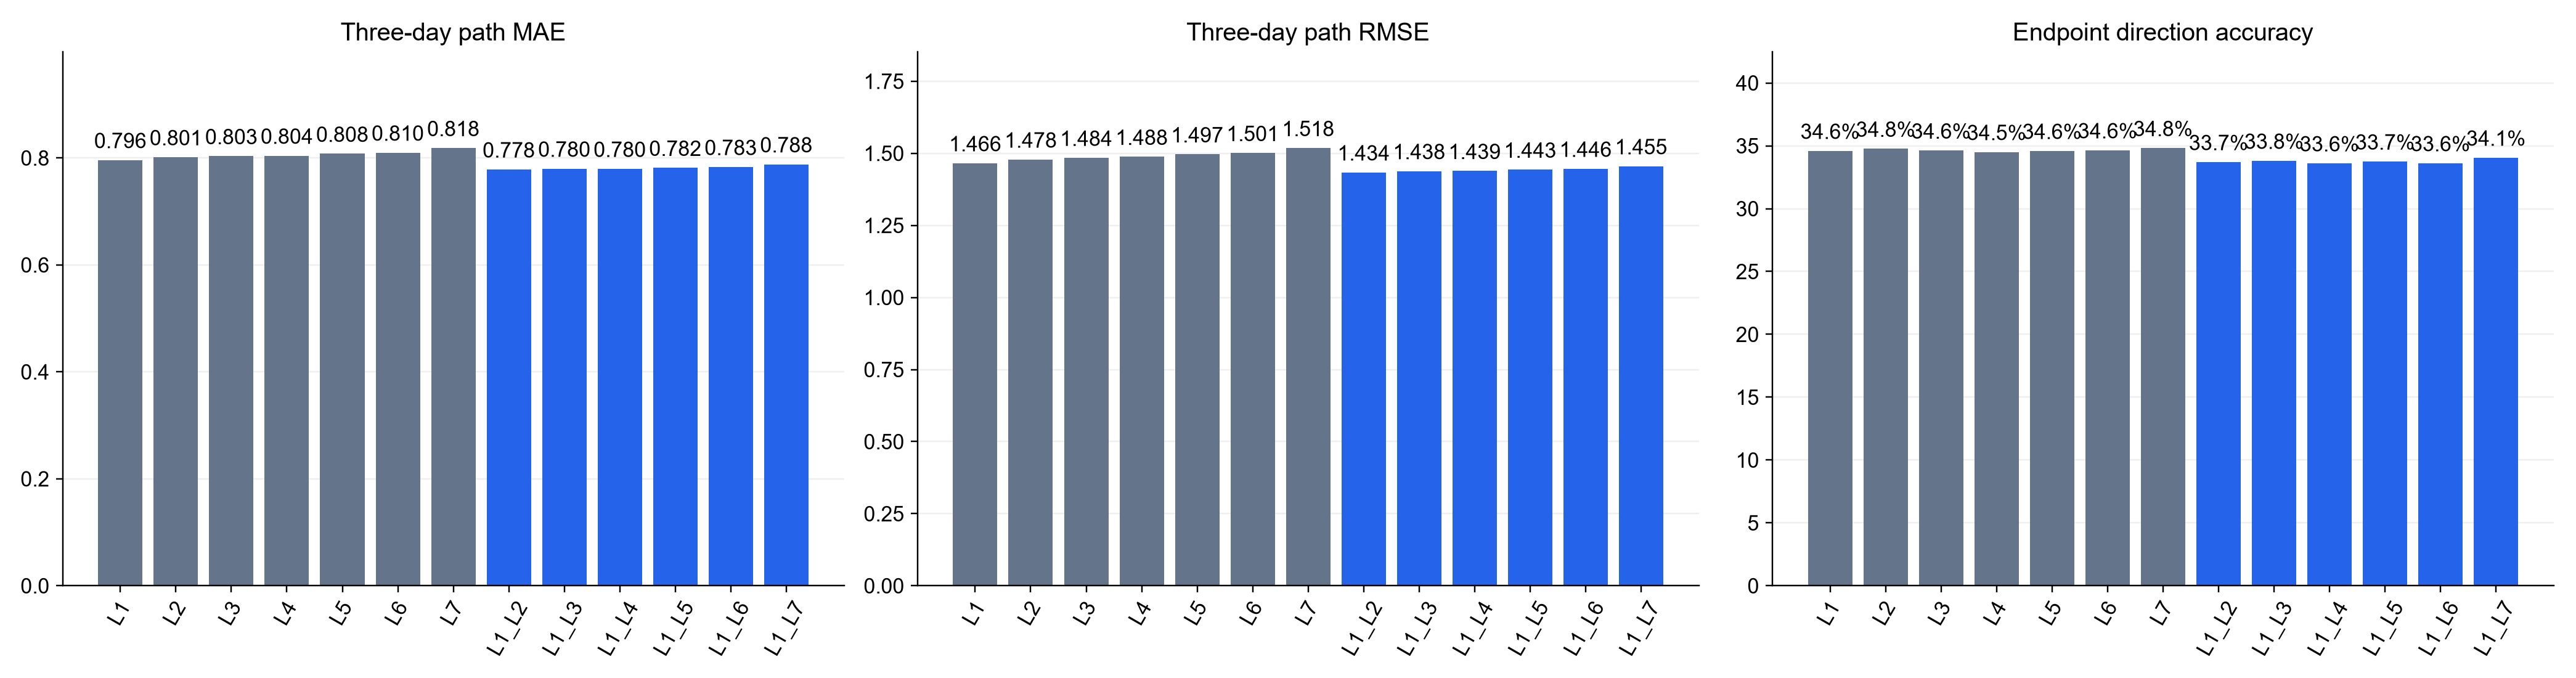

In [3]:
display(pd.read_csv(OUTPUT/'paired_comparisons.csv'))
display(pd.read_csv(OUTPUT/'initial_training_lag_inference.csv'))
display(pd.read_csv(OUTPUT/'validation_residual_correlations.csv'))
from IPython.display import Image, display
display(Image(filename=str(OUTPUT/'figures'/'lag_prediction_comparison.png')))

## Reading the outputs

1. `validation_metrics.csv`: compare MAE, RMSE and endpoint direction. Lower errors are better. Direction accuracy must also be compared with the observed flat-class share.
2. `paired_comparisons.csv`: positive delta means lower MAE than L1; confidence intervals and adjusted p-values describe exploratory uncertainty. Twelve comparisons are adjusted together per HAC bandwidth.
3. `initial_training_lag_inference.csv`: coefficients and uncertainty from the first training fit only. A small p-value is evidence of conditional association under the stated assumptions, not proof of predictive superiority.
4. `validation_residual_correlations.csv`: residual correlations at 1 and 7 days, after removing each ZIP's validation-period mean error. Values near zero indicate less remaining linear temporal correlation; no universal pass threshold is imposed.
5. `training_audit.csv`: verifies dates, inputs and training target cutoffs.

Choose conclusions from the results, not a preselected claim that L1 and L7 must win. A lag's age is not the forecast horizon or warning lead time.


In [4]:
display(Image(filename=str(OUTPUT/'figures'/'lag_coefficients.png')))
display(Image(filename=str(OUTPUT/'figures'/'residual_correlations.png')))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\41240\\OneDrive\\文档\\GitHub\\practicum-project\\Weikun\\mentor_followup_outputs\\2026-11-04\\lag_sweep\\figures\\lag_coefficients.png'